# Day 14 — Voter Turnout Analytics

**Question:** how does voter turnout differ across US states and over time, and
which demographic indicators move with it — described only, with every number
traceable to its source and no claim about what caused any difference?

**Scope (Victor, voice call 2026-11-20):** descriptive ONLY — no predictive model.
Turnout map + evidence-limited insights memo. Outliers are screened during
skewness screening and reported as found, never dropped silently.

**Data:** University of Florida Election Lab (Michael McDonald), general-election
turnout rates 1980–2022 v1.2 and 2024 v0.4, CC BY 4.0. Primary metric: **VEP
turnout = ballots counted ÷ voting-eligible population**. VAP turnout is reported
alongside, never as a substitute. EAVS 2024 is a cross-check on the 2024 numerator
only. Comparisons are within cycle type only (presidential vs presidential,
midterm vs midterm).

In [1]:
from pathlib import Path

import pandas as pd

def _find_root() -> Path:
    """Project root, resolved from this notebook file (Day 1 lesson e)."""
    try:
        here = Path(__file__).resolve().parent
    except NameError:
        here = Path.cwd()
    for parent in [here, *here.parents]:
        if (parent / "data" / "processed" / "turnout_long.csv").exists():
            return parent
    raise FileNotFoundError("could not find data/processed/turnout_long.csv above the notebook")

ROOT = _find_root()
PROC = ROOT / "data" / "processed"
import json

record = json.loads((PROC / "data_source.json").read_text(encoding="utf-8"))
long = pd.read_csv(PROC / "turnout_long.csv")
national = pd.read_csv(PROC / "national_series.csv")
state_2024 = pd.read_csv(PROC / "state_2024.csv")
corr = pd.read_csv(PROC / "correlations.csv")
outliers = pd.read_csv(PROC / "outliers.csv")
print(f"root: {ROOT}")
print(f"turnout_long: {len(long):,} rows ({long['year'].min()}–{long['year'].max()})")
print(f"national_series: {len(national)} rows; state_2024: {len(state_2024)} rows")

root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-14-voter-turnout-analytics
turnout_long: 1,196 rows (1980–2024)
national_series: 23 rows; state_2024: 52 rows


## Audit — what was filed, what is missing

Column 5 of the UF files is parsed by content, never by header: a URL is a
source link, digits are the vote-for-highest-office count, blank is missing.
Pre-2010 state ballots are null by design and stay null; the national VEP
turnout rate is not reported in the file for 1980–1996.

In [2]:
counts = record["cleaning_counts"]
print("rows per file:", counts["rows_1980_2022_file"], "+", counts["rows_2024_file"],
      "=", counts["rows_concatenated"], "| cleaned:", counts["rows_cleaned"],
      "| duplicates dropped:", counts["duplicate_rows_dropped"])
print("column-5 1980–2022:", counts["column5_1980_2022"])
print("column-5 2024:", counts["column5_2024"])
print("null ballots per year:", counts["null_ballots_per_year"])
print("null ballots total:", counts["null_ballots_total"])
print("VEP reconciliation: flagged rows =",
      counts["vep_reconciliation_flagged_rows"],
      "| max relative difference =",
      f"{counts['vep_reconciliation_max_rel_diff'] * 100:.4f}% (tolerance 0.5%)")
rec = record["recompute_check"]
print("recompute check: rows =", rec["rows_checked"],
      "| max |recomputed − file| =", f"{rec['max_abs_diff_pp']:.4f} pp (tolerance 0.05 pp)",
      "| rows over tolerance =", rec["rows_over_tolerance"])
print("spot-checks:", {k: v["file_rate"] for k, v in rec["spot_checks"].items()})
assert counts["rows_cleaned"] == 1196
assert rec["rows_over_tolerance"] == 0

rows per file: 1144 + 52 = 1196 | cleaned: 1196 | duplicates dropped: 0
column-5 1980–2022: {'blank': 54, 'digits': 1039, 'url': 51}
column-5 2024: {'blank': 1, 'digits': 0, 'url': 51}
null ballots per year: {'1980': 18, '1982': 20, '1984': 19, '1986': 18, '1988': 19, '1990': 18, '1992': 16, '1994': 13, '1996': 13, '1998': 13, '2000': 13, '2002': 16, '2004': 4, '2006': 6, '2008': 3}
null ballots total: 209
VEP reconciliation: flagged rows = 0 | max relative difference = 0.0580% (tolerance 0.5%)
recompute check: rows = 987 | max |recomputed − file| = 0.0226 pp (tolerance 0.05 pp) | rows over tolerance = 0
spot-checks: {'2022 United States': 46.12, '2024 Arkansas': 54.06, '2024 California': 62.26, '2024 Colorado': 73.4, '2024 United States': 64.3}


## Q2 — How has turnout moved over time, 1980–2024?

National VEP turnout, split by cycle type. Presidential years are compared with
presidential years and midterms with midterms; a presidential-to-midterm change
is a cycle-type change, not a trend. Pre-2010 national figures are estimated.

In [3]:
display(national[["year", "cycle_type", "vep_turnout_rate", "vap_turnout_rate",
                  "vep_turnout_pp_change_same_cycle", "national_estimated"]])
row_2024 = national[national["year"] == 2024].iloc[0]
row_2022 = national[national["year"] == 2022].iloc[0]
print(f"2024 (presidential): {row_2024['vep_turnout_rate']:.2f}% "
      f"({row_2024['vep_turnout_pp_change_same_cycle']:+.2f} pp vs 2020)")
print(f"2022 (midterm): {row_2022['vep_turnout_rate']:.2f}% "
      f"({row_2022['vep_turnout_pp_change_same_cycle']:+.2f} pp vs 2018)")
print("Series high (presidential): 2020, 65.99%")
print("Series high (midterm): 2018, 50.05% (+13.44 pp vs 2014)")
assert float(row_2024["vep_turnout_rate"]) == 64.30
assert float(row_2022["vep_turnout_rate"]) == 46.12

,year,cycle_type,vep_turnout_rate,vap_turnout_rate,vep_turnout_pp_change_same_cycle,national_estimated
0,1980,presidential,NaN,NaN,NaN,True
1,1982,midterm,NaN,NaN,NaN,True
2,1984,presidential,NaN,NaN,NaN,True
3,1986,midterm,NaN,NaN,NaN,True
4,1988,presidential,NaN,NaN,NaN,True
5,1990,midterm,NaN,NaN,NaN,True
6,1992,presidential,NaN,NaN,NaN,True
7,1994,midterm,NaN,NaN,NaN,True
8,1996,presidential,NaN,NaN,NaN,True
9,1998,midterm,39.31,36.44,NaN,True


2024 (presidential): 64.30% (-1.69 pp vs 2020)
2022 (midterm): 46.12% (-3.93 pp vs 2018)
Series high (presidential): 2020, 65.99%
Series high (midterm): 2018, 50.05% (+13.44 pp vs 2014)


## Q1 — How does turnout differ across states?

2024 VEP turnout by state (rank 1 = highest), with the pp change since 2020 —
the last presidential year, so the comparison is like-with-like. The US total
is shown separately, never ranked.

In [4]:
states = state_2024[~state_2024["is_national"].astype(bool)].sort_values("rank_vep")
display(states[["rank_vep", "state", "vep_turnout_rate", "vap_turnout_rate",
                "pp_change_vs_2020"]].head(10))
display(states[["rank_vep", "state", "vep_turnout_rate", "vap_turnout_rate",
                "pp_change_vs_2020"]].tail(10))
top = states.iloc[0]
bottom = states.iloc[-1]
print(f"Highest 2024: {top['state']} {top['vep_turnout_rate']:.2f}% "
      f"(rank 1, {top['pp_change_vs_2020']:+.2f} pp vs 2020)")
print(f"Lowest 2024: {bottom['state']} {bottom['vep_turnout_rate']:.2f}% "
      f"(rank 51, {bottom['pp_change_vs_2020']:+.2f} pp vs 2020)")
us = state_2024[state_2024["is_national"].astype(bool)].iloc[0]
print(f"US total 2024: {us['vep_turnout_rate']:.2f}% (not ranked)")
assert top["state"] == "Wisconsin" and float(top["vep_turnout_rate"]) == 76.66
assert bottom["state"] == "Hawaii" and float(bottom["vep_turnout_rate"]) == 50.26

,rank_vep,state,vep_turnout_rate,vap_turnout_rate,pp_change_vs_2020
0,1.0,Wisconsin,76.66,73.07,1.62
1,2.0,Minnesota,76.50,73.05,-2.71
2,3.0,Michigan,74.85,71.70,1.58
3,4.0,Maine,74.55,72.76,-0.32
4,5.0,New Hampshire,73.74,71.78,-0.22
5,6.0,Colorado,73.40,68.55,-3.29
6,7.0,Oregon,71.87,67.65,-3.46
7,8.0,Virginia,71.46,65.84,-0.33
8,9.0,Pennsylvania,71.44,68.36,1.51
9,10.0,Iowa,70.95,67.20,-1.09


,rank_vep,state,vep_turnout_rate,vap_turnout_rate,pp_change_vs_2020
41,42.0,New Mexico,59.71,55.39,-0.78
42,43.0,Indiana,59.05,55.94,-2.01
43,44.0,Alabama,58.70,56.46,-2.76
44,45.0,Tennessee,57.92,54.50,-1.32
45,46.0,Mississippi,57.75,55.10,-2.88
46,47.0,Texas,56.83,48.48,-2.96
47,48.0,West Virginia,55.56,54.41,-1.63
48,49.0,Arkansas,54.06,49.76,-2.11
49,50.0,Oklahoma,53.46,50.29,-0.97
50,51.0,Hawaii,50.26,45.79,-5.09


Highest 2024: Wisconsin 76.66% (rank 1, +1.62 pp vs 2020)
Lowest 2024: Hawaii 50.26% (rank 51, -5.09 pp vs 2020)
US total 2024: 64.30% (not ranked)


## Skewness screening and outliers

Skewness is computed within each cycle type (pooled, labelled as pooled).
States outside the 1.5×IQR fence or with |z| > 3 within their cycle type are
flagged and listed — and stay in every chart and table.

In [5]:
derived = record["derived_tables"]
print(f"Skewness (presidential years pooled): {derived['skewness_presidential_pooled']:.2f}")
print(f"Skewness (midterm years pooled): {derived['skewness_midterm_pooled']:.2f}")
print(f"Flagged outliers: {len(outliers)} rows (2024 pass: "
      f"{len(derived['outliers_2024'])} — no state flagged in 2024)")
display(outliers)
# Every flagged row must still be present in the long table.
for _, row in outliers.iterrows():
    match = long[(long["year"] == int(row["year"])) &
                 (long["state_abv"] == row["state_abv"])]
    assert len(match) == 1
    assert float(match.iloc[0]["vep_turnout_rate"]) == row["vep_turnout_rate"]
print("All flagged rows are still present in turnout_long.csv.")

Skewness (presidential years pooled): -0.27
Skewness (midterm years pooled): 0.06
Flagged outliers: 5 rows (2024 pass: 0 — no state flagged in 2024)


,year,cycle_type,state_abv,vep_turnout_rate,rule,statistic_value
0,1980,presidential,DC,37.90,iqr+z,-3.260505
1,1980,presidential,SC,42.35,iqr,-2.640205
2,1988,presidential,SC,42.46,iqr,-2.624872
3,1996,presidential,NV,41.23,iqr,-2.796326
4,2016,presidential,HI,43.19,iqr,-2.523115


All flagged rows are still present in turnout_long.csv.


## Q3 — Which demographic indicators move with turnout?

State-level associations for 2024 (n = 51, DC included, US total excluded),
reported as Pearson r + p and Spearman ρ + p. **Association only — this does
not show that any indicator caused turnout to change.** No model is fitted.

In [6]:
display(corr)
noncit = corr[corr["indicator"] == "noncitizen_pct"].iloc[0]
felon = corr[corr["indicator"] == "felon_share_vap"].iloc[0]
overseas = corr[corr["indicator"] == "overseas_share_vep"].iloc[0]
print(f"Noncitizen share: Pearson r = {noncit['pearson_r']:.2f} "
      f"(p = {noncit['pearson_p']:.3f}, n = {int(noncit['n'])}) — no clear association in these data.")
print(f"Ineligible-felon share: Pearson r = {felon['pearson_r']:.2f} "
      f"(p = {felon['pearson_p']:.4f}, n = {int(felon['n'])}) — moves with turnout; association only.")
print(f"Overseas eligible share: n = {int(overseas['n'])} — the lab does not apportion "
      "eligible overseas voters to states, so no state-level association is computable.")
assert int(noncit["n"]) == 51 and int(felon["n"]) == 51 and int(overseas["n"]) == 0
assert abs(float(felon["pearson_r"]) - (-0.40)) < 0.01

,indicator,scope,n,pearson_r,pearson_p,spearman_r,spearman_p
0,noncitizen_pct,2024_states,51,-0.067310,0.638851,-0.035703,0.803571
1,felon_share_vap,2024_states,51,-0.402436,0.003416,-0.403720,0.003305
2,overseas_share_vep,2024_states,0,NaN,NaN,NaN,NaN


Noncitizen share: Pearson r = -0.07 (p = 0.639, n = 51) — no clear association in these data.
Ineligible-felon share: Pearson r = -0.40 (p = 0.0034, n = 51) — moves with turnout; association only.
Overseas eligible share: n = 0 — the lab does not apportion eligible overseas voters to states, so no state-level association is computable.


## Charts

The four charts, drawn from the committed processed tables. The map re-renders
from the Census shapefile when it is present; when it is absent (offline run
after the build), the committed PNG stands and the re-render is skipped — the
notebook still finishes with 0 errors.

Shapefile absent — map re-render skipped; showing the committed PNG.


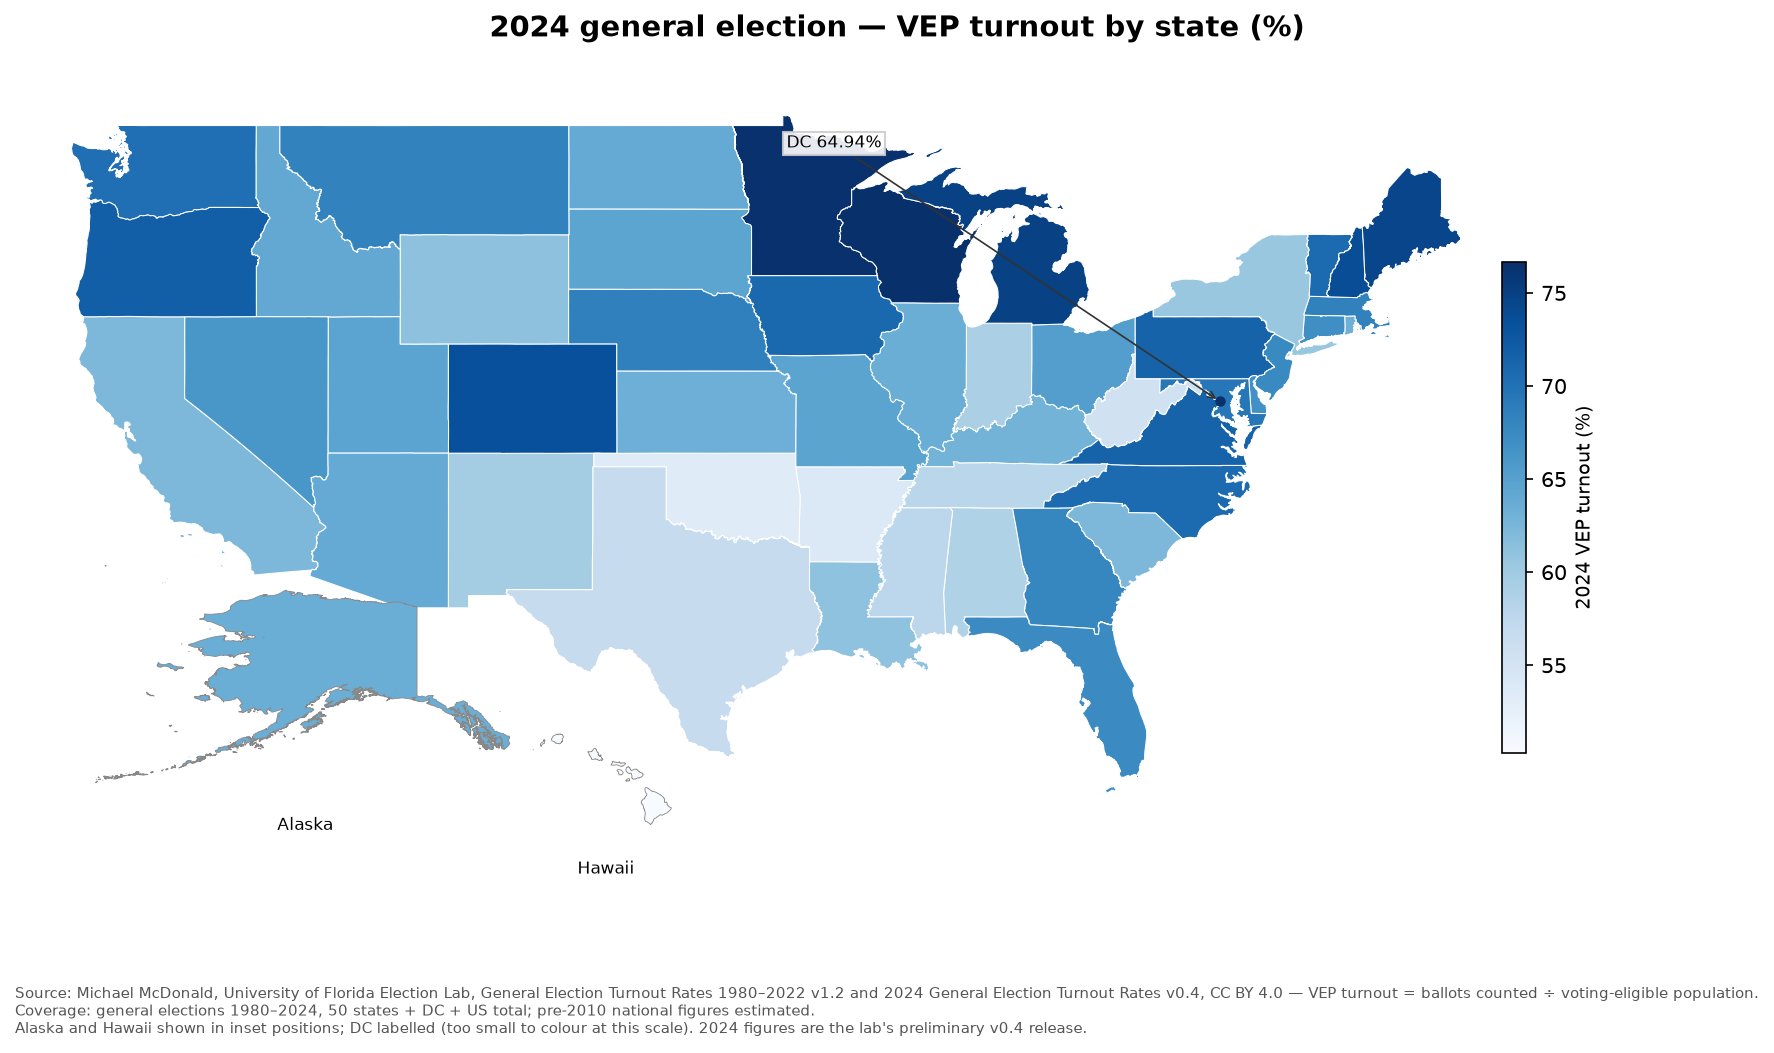

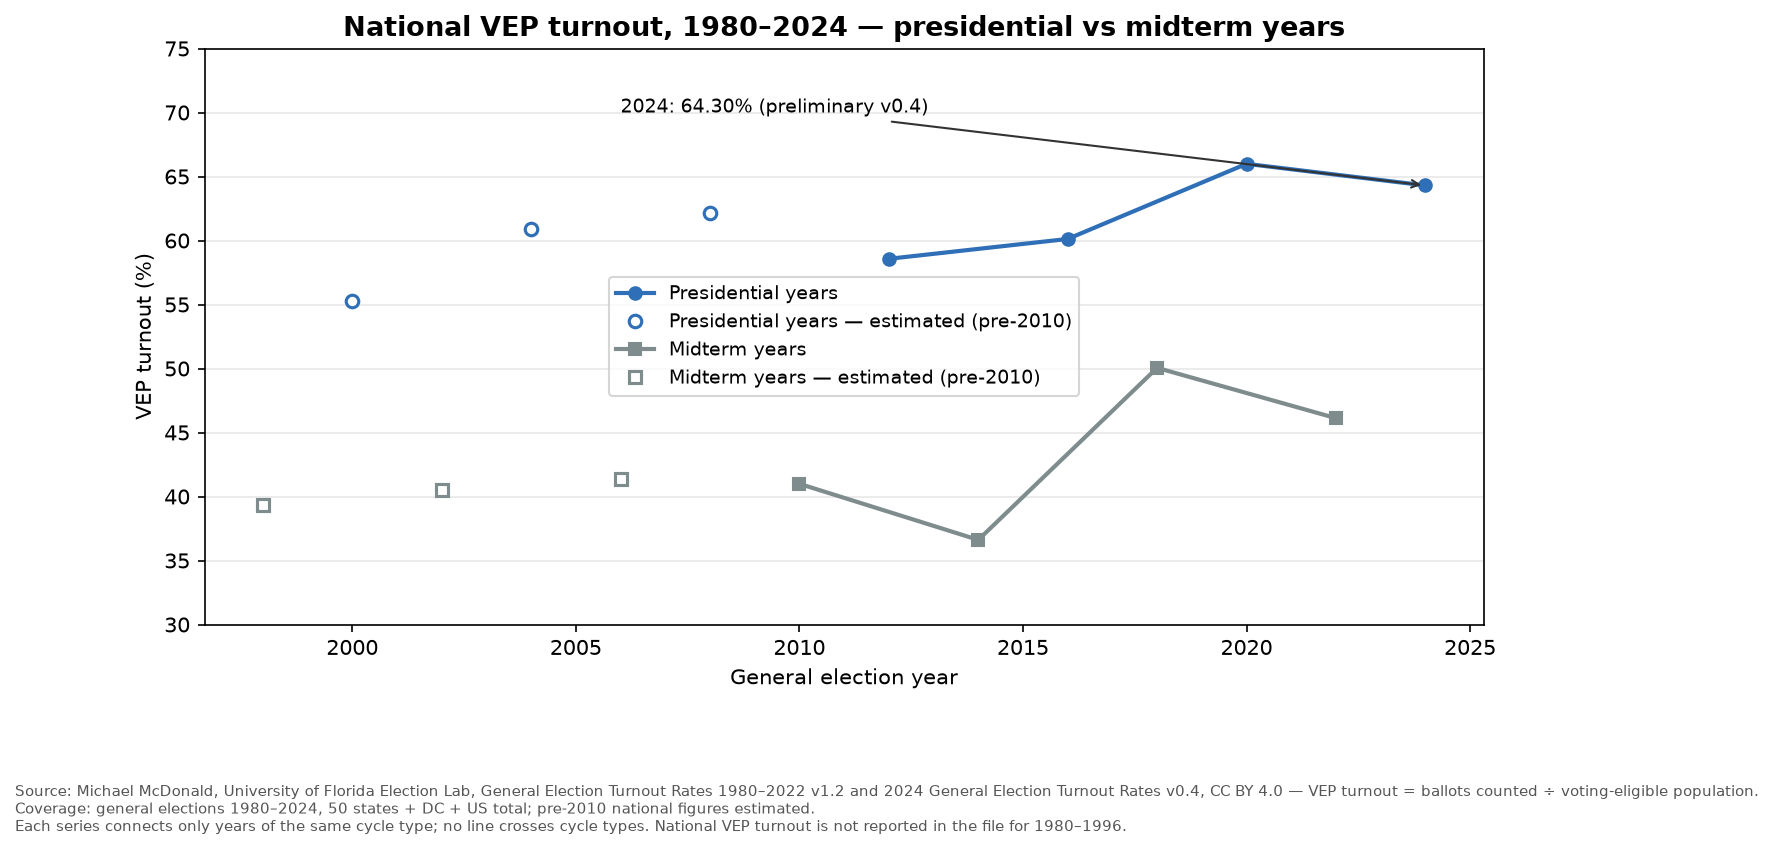

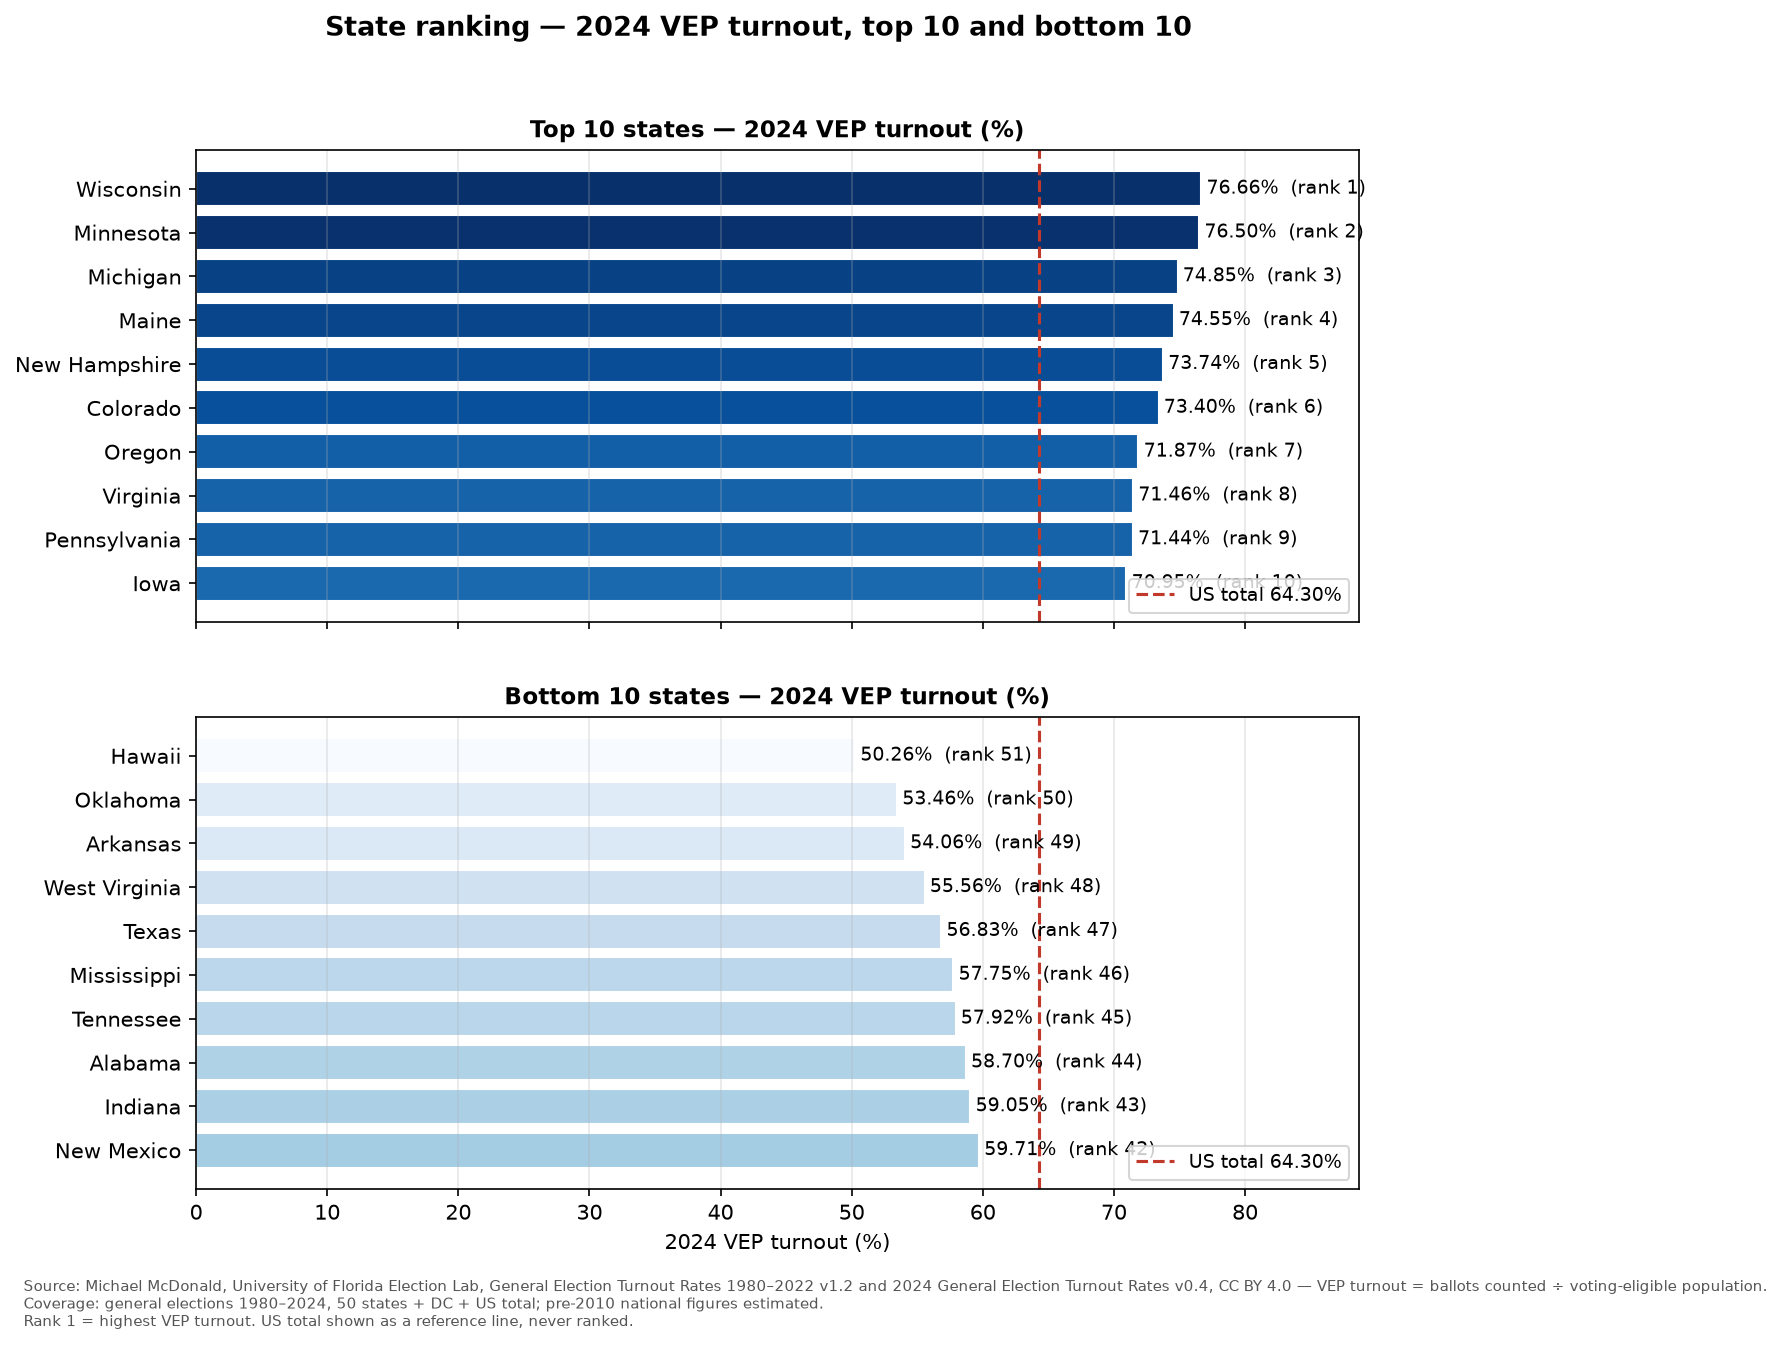

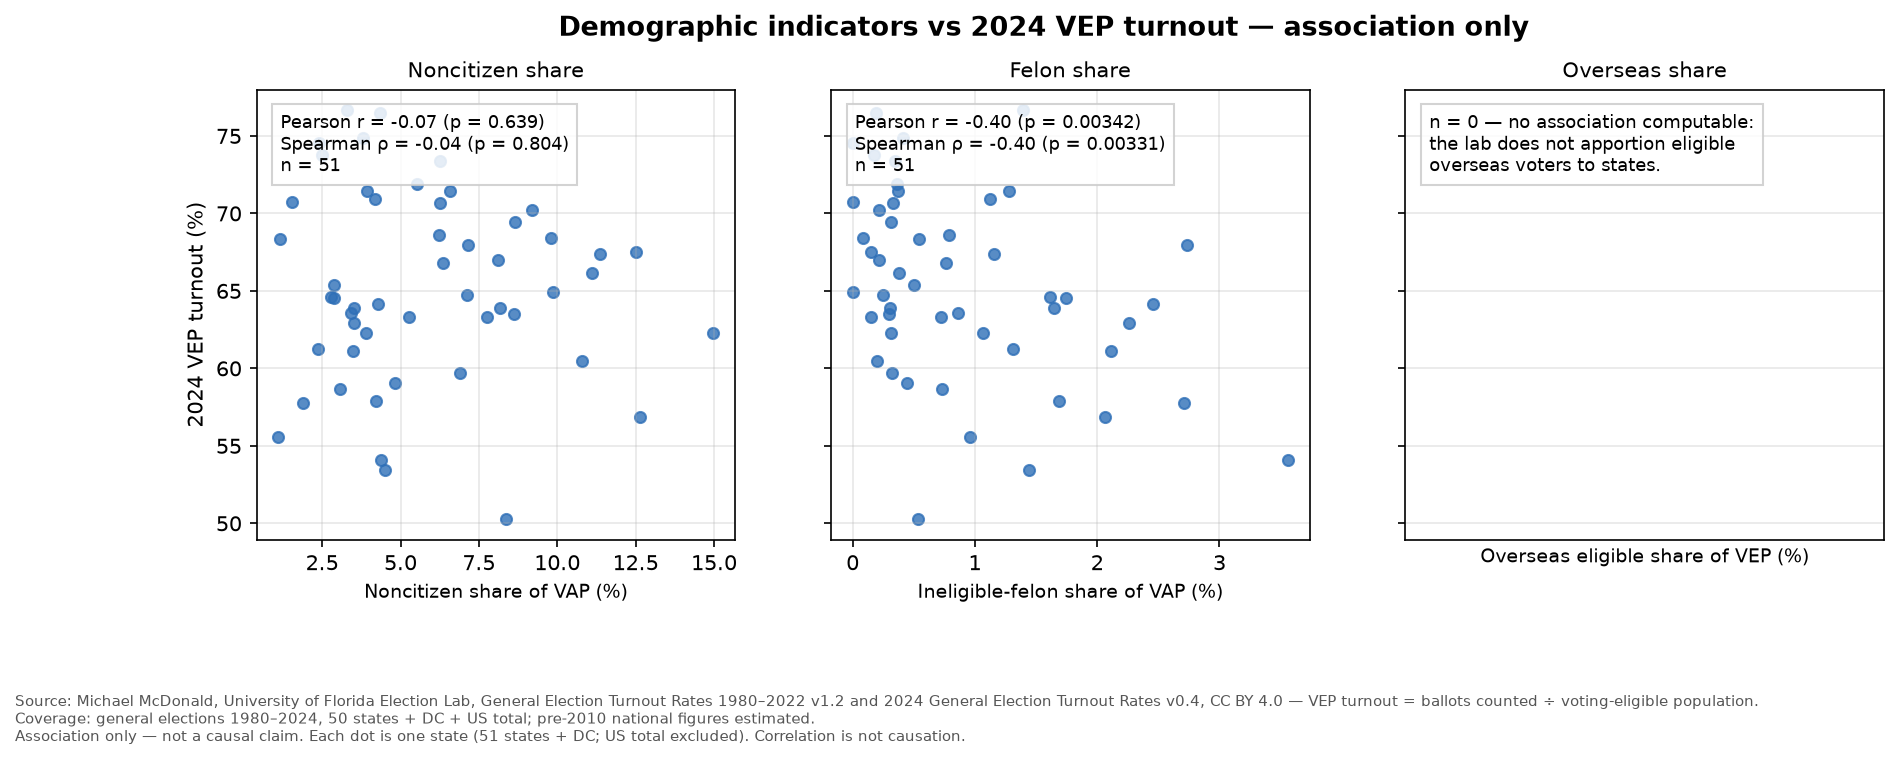

In [7]:
from IPython.display import Image, display as _display

shp = list((ROOT / "data" / "raw" / "shapefile").glob("*.shp")) if (ROOT / "data" / "raw" / "shapefile").exists() else []
if shp:
    import sys
    sys.path.insert(0, str(ROOT))
    from src.make_charts import build_chart_01_map
    rebuilt = build_chart_01_map(ROOT)
    assert rebuilt is not None and rebuilt.exists()
    assert len(state_2024[~state_2024["is_national"].astype(bool)]) == 51
    print("Map re-rendered from the shapefile; source table still has 51 jurisdictions.")
else:
    print("Shapefile absent — map re-render skipped; showing the committed PNG.")
for name in ("01_turnout_map_2024", "02_turnout_over_time",
             "03_state_ranking_2024", "04_demographic_scatter"):
    _display(Image(filename=str(ROOT / "outputs" / "charts" / f"{name}.png")))

## SQL check

The same two questions answered twice — once in pandas, once in SQL on the
committed `turnout_long.csv` loaded into an in-memory SQLite database — and
asserted equal. This is the day's SQL element; no `.pbix` is built.

In [8]:
import sqlite3

states_long = long[~long["is_national"]]
pandas_means = states_long.groupby("cycle_type")["vep_turnout_rate"].mean()
pandas_top = states_long[states_long["year"] == 2024].sort_values(
    ["vep_turnout_rate", "state_abv"], ascending=[False, True]).iloc[0]
conn = sqlite3.connect(":memory:")
states_long.to_sql("turnout", conn, index=False)
sql_means = dict(conn.execute(
    "SELECT cycle_type, AVG(vep_turnout_rate) FROM turnout "
    "WHERE vep_turnout_rate IS NOT NULL GROUP BY cycle_type").fetchall())
sql_top = conn.execute(
    "SELECT state_abv, vep_turnout_rate FROM turnout WHERE year = 2024 "
    "ORDER BY vep_turnout_rate DESC, state_abv ASC LIMIT 1").fetchone()
conn.close()
for cycle in ("presidential", "midterm"):
    print(f"Mean VEP turnout ({cycle}): pandas {pandas_means[cycle]:.4f} | SQL {sql_means[cycle]:.4f}")
    assert abs(float(pandas_means[cycle]) - sql_means[cycle]) < 1e-9
print(f"Top state 2024: pandas {pandas_top['state_abv']} {pandas_top['vep_turnout_rate']:.2f}% "
      f"| SQL {sql_top[0]} {sql_top[1]:.2f}%")
assert sql_top[0] == str(pandas_top["state_abv"])
assert abs(sql_top[1] - float(pandas_top["vep_turnout_rate"])) < 1e-9
print("SQL and pandas agree.")

Mean VEP turnout (presidential): pandas 61.2907 | SQL 61.2907
Mean VEP turnout (midterm): pandas 45.1203 | SQL 45.1203
Top state 2024: pandas WI 76.66% | SQL WI 76.66%
SQL and pandas agree.
